# Đánh giá ngoài (External Validation) — PAD-UFES-20 + BALD

Đánh giá model tốt nhất (`07_train_improved.ipynb`) trên 2 dataset ISIC khác, đã loại các ảnh trùng với dataset gốc.

- **PAD-UFES-20** (collection #406) — ảnh clinical close-up chụp bằng smartphone, khác domain dermoscopy lúc train.
- **BALD** (collection #410) — ảnh dermoscopy tổn thương vùng acral (lòng bàn tay/bàn chân), nguồn International Dermoscopy Society.


##### 1. Load metadata

In [2]:
import numpy as np
import pandas as pd

df_pad = pd.read_csv('../test/pad-ufes-20/metadata.csv')
print(df_pad.shape)
df_pad.head()

(2298, 25)


,isic_id,public,copyright_license,attribution,full_url,full_size_bytes,pixels_x,pixels_y,image_type,anatom_site_1,...,age_approx,lesion_id,patient_id,anatom_site_3,anatom_site_special,anatom_site_4,anatom_site_5,fitzpatrick_skin_type,sex,clin_size_long_diam_mm
0,ISIC_0601025,True,CC-BY,Federal University of Espírito Santo (UFES),https://isic-archive.s3.amazonaws.com/images/I...,7884,256,256,clinical: close-up,Trunk,...,30,IL_6630725,IP_4812172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ISIC_4127417,True,CC-BY,Federal University of Espírito Santo (UFES),https://isic-archive.s3.amazonaws.com/images/I...,14102,535,534,clinical: close-up,Upper extremity,...,5,IL_2026080,IP_9281843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ISIC_9128384,True,CC-BY,Federal University of Espírito Santo (UFES),https://isic-archive.s3.amazonaws.com/images/I...,23184,531,531,clinical: close-up,Trunk,...,5,IL_8278335,IP_9281843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ISIC_2103575,True,CC-BY,Federal University of Espírito Santo (UFES),https://isic-archive.s3.amazonaws.com/images/I...,99050,943,942,clinical: close-up,Trunk,...,75,IL_7308584,IP_2631070,Anterior chest,NaN,NaN,NaN,NaN,NaN,NaN
4,ISIC_0632634,True,CC-BY,Federal University of Espírito Santo (UFES),https://isic-archive.s3.amazonaws.com/images/I...,50817,571,571,clinical: close-up,Head and neck,...,35,IL_7960581,IP_1613423,Scalp,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df_bald = pd.read_csv('../test/bald/metadata.csv')
print(df_bald.shape)
df_bald.head()

(666, 18)


,isic_id,public,copyright_license,attribution,full_url,full_size_bytes,pixels_x,pixels_y,image_type,sex,anatom_site_special,anatom_site_1,anatom_site_2,anatom_site_3,diagnosis_1,diagnosis_2,diagnosis_3,age_approx
0,ISIC_6846234,True,CC-BY-NC,International Dermoscopy Society,https://isic-archive.s3.amazonaws.com/images/I...,20943,600,450,dermoscopic,male,acral palms or soles,Lower extremity,Foot,Sole of foot,Malignant,Malignant melanocytic proliferations (Melanoma),Melanoma in situ,70
1,ISIC_0536538,True,CC-BY-NC,International Dermoscopy Society,https://isic-archive.s3.amazonaws.com/images/I...,26990,600,450,dermoscopic,male,acral palms or soles,Lower extremity,Foot,Sole of foot,Malignant,Malignant melanocytic proliferations (Melanoma),Melanoma Invasive,70
2,ISIC_2978684,True,CC-BY-NC,International Dermoscopy Society,https://isic-archive.s3.amazonaws.com/images/I...,30357,600,450,dermoscopic,male,acral palms or soles,Lower extremity,Foot,Sole of foot,Malignant,Malignant melanocytic proliferations (Melanoma),Melanoma Invasive,60
3,ISIC_8989475,True,CC-BY-NC,International Dermoscopy Society,https://isic-archive.s3.amazonaws.com/images/I...,30088,600,450,dermoscopic,male,acral palms or soles,Lower extremity,Foot,Sole of foot,Malignant,Malignant melanocytic proliferations (Melanoma),Melanoma Invasive,50
4,ISIC_3129360,True,CC-BY-NC,International Dermoscopy Society,https://isic-archive.s3.amazonaws.com/images/I...,24875,600,450,dermoscopic,female,acral palms or soles,Upper extremity,Hand,Palm of hand,Malignant,Malignant melanocytic proliferations (Melanoma),Melanoma Invasive,40


##### 2. Lọc nhãn, chuẩn hóa feature, gộp test set

- Chỉ giữ melanoma/nevus theo `diagnosis_3` (model chỉ phân loại 2 lớp này). PAD-UFES-20 bỏ thêm các ca `diagnosis_1 == 'Indeterminate'` (toàn bộ là actinic keratosis).
- BALD: loại 6 ảnh trùng với ảnh trong dataset gốc.
- Map vị trí tổn thương về đúng 8 category model đã học:
  - PAD-UFES-20: `anatom_site_1` → `upper extremity` / `lower extremity` / `head/neck`. Riêng `Trunk` không biết là thân trước hay thân sau nên coi như thiếu.
  - BALD: `anatom_site_special == 'acral palms or soles'` → `palms/soles` (khớp cách bộ train gán: 340/366 ca acral palms/soles trong `data/raw/metadata.csv` có `anatom_site_general = 'palms/soles'`).

In [4]:
PAD_SITE_MAP = {
    'Upper extremity': 'upper extremity',
    'Lower extremity': 'lower extremity',
    'Head and neck': 'head/neck',
}

# Ảnh BALD trùng với ảnh trong dataset gốc (phát hiện bằng perceptual hash, đã kiểm tra bằng mắt)
BALD_DUPLICATES = [
    'ISIC_0253805', 'ISIC_6177828', 'ISIC_6846234',
    'ISIC_0558386', 'ISIC_4464596', 'ISIC_8082578',
]

pad = df_pad[
    (df_pad['diagnosis_1'] != 'Indeterminate')
    & df_pad['diagnosis_3'].isin(['Nevus', 'Melanoma, NOS'])
].copy()
pad['label'] = pad['diagnosis_3'].map({'Nevus': 'nevus', 'Melanoma, NOS': 'melanoma'})
pad['age'] = pad['age_approx']
pad['anatom_site'] = pad['anatom_site_1'].map(PAD_SITE_MAP)  # 'Trunk' -> NaN
pad['image_path'] = '../test/pad-ufes-20/images/' + pad['isic_id'] + '.jpg'
pad['source'] = 'pad-ufes-20'

bald = df_bald[
    df_bald['diagnosis_3'].isin(['Nevus', 'Melanoma Invasive', 'Melanoma in situ'])
    & ~df_bald['isic_id'].isin(BALD_DUPLICATES)
].copy()
bald['label'] = np.where(bald['diagnosis_3'] == 'Nevus', 'nevus', 'melanoma')
bald['age'] = bald['age_approx']
bald['anatom_site'] = np.where(bald['anatom_site_special'] == 'acral palms or soles', 'palms/soles', None)
bald['image_path'] = '../test/bald/images/' + bald['isic_id'] + '.jpg'
bald['source'] = 'bald'

cols = ['isic_id', 'source', 'label', 'age', 'sex', 'anatom_site', 'image_path']
df_test = pd.concat([pad[cols], bald[cols]], ignore_index=True)

print('Test set (PAD-UFES-20 + BALD):', df_test.shape)
pd.crosstab(df_test['source'], df_test['label'])

Test set (PAD-UFES-20 + BALD): (956, 7)


label,melanoma,nevus
source,,
bald,140,520
pad-ufes-20,52,244


Đánh dấu mỗi mẫu thiếu những feature nào, để sau này báo cáo metrics riêng cho từng nhóm.

In [5]:
FEATURES = ['age', 'sex', 'anatom_site']

missing = df_test[FEATURES].isna()
df_test['thiếu'] = missing.apply(lambda r: ' + '.join(f for f in FEATURES if r[f]), axis=1).replace('', 'không thiếu')

pd.crosstab(df_test['thiếu'], df_test['label'], margins=True, margins_name='Tổng')

label,melanoma,nevus,Tổng
thiếu,,,
anatom_site,30,89,119
không thiếu,162,501,663
sex,0,82,82
sex + anatom_site,0,92,92
Tổng,192,764,956


##### 3. Tiền xử lý metadata — thống kê của tập train + fallback khi thiếu

Lặp lại đúng các bước của `03_imputation.ipynb`: `U50`/`U60`/`U70` từ tuổi, `sex` → binary, `StandardScaler` cho tuổi **fit trên `data/processed/train.csv`** (không fit lại trên dữ liệu test), one-hot vị trí tổn thương. Thứ tự cột khớp `METADATA_COLS` của `04_image_pipeline.ipynb`.

Fallback khi thiếu (giống desktop app):

| Feature thiếu | Giá trị đưa vào model |
|---|---|
| Giới tính | `sex_encoded = SEX_MALE_RATIO` (tỷ lệ nam trong train) |
| Vị trí tổn thương | 8 cột one-hot `anatom_*` đều bằng 0 |
| Tuổi | tuổi trung bình của train (`age_approx_scaled = 0`) |

In [6]:
from sklearn.preprocessing import StandardScaler

METADATA_COLS = [
    'U50', 'U60', 'U70', 'sex_encoded', 'age_approx_scaled',
    'anatom_anterior torso', 'anatom_head/neck', 'anatom_lateral torso',
    'anatom_lower extremity', 'anatom_oral/genital', 'anatom_palms/soles',
    'anatom_posterior torso', 'anatom_upper extremity',
]

df_train_ref = pd.read_csv('../data/processed/train.csv')
age_scaler = StandardScaler().fit(df_train_ref[['age_approx']])
AGE_MEAN = age_scaler.mean_[0]
SEX_MALE_RATIO = df_train_ref['sex_encoded'].mean()
print('Tuổi (từ train): mean =', AGE_MEAN, '| std =', age_scaler.scale_[0])
print('SEX_MALE_RATIO =', SEX_MALE_RATIO)


def build_metadata(df):
    age = df['age'].fillna(AGE_MEAN)
    feats = pd.DataFrame(index=df.index)
    feats['U50'] = (age > 50).astype(float)
    feats['U60'] = (age > 60).astype(float)
    feats['U70'] = (age > 70).astype(float)
    feats['sex_encoded'] = df['sex'].map({'male': 1.0, 'female': 0.0}).fillna(SEX_MALE_RATIO)
    feats['age_approx_scaled'] = age_scaler.transform(age.to_frame('age_approx'))[:, 0]
    for col in METADATA_COLS[5:]:
        feats[col] = (df['anatom_site'] == col[len('anatom_'):]).astype(float)  # thiếu vị trí -> toàn 0
    return feats[METADATA_COLS].to_numpy(dtype='float32')


metadata_test = build_metadata(df_test)
print('Metadata:', metadata_test.shape, '| có NaN:', np.isnan(metadata_test).any())

Tuổi (từ train): mean = 52.01913988657845 | std = 17.76104772808917
SEX_MALE_RATIO = 0.5172495274102079
Metadata: (956, 13) | có NaN: False


##### 4. Load model từ `07_train_improved.ipynb`

Kiến trúc `MultimodalModel` chép nguyên từ 07 (EfficientNet-B0 1280 chiều + MLP metadata 32 chiều). Backbone khởi tạo `weights=None` vì toàn bộ trọng số đã train sẽ load từ checkpoint ngay sau.

`CHECKPOINT_PATH` theo đúng quy ước local của 07: file `best_model_improved.pt` (tải từ Google Drive) đặt cạnh notebook.

In [7]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0


class MultimodalModel(nn.Module):
    def __init__(self, n_metadata_features, image_feature_dim=1280, metadata_hidden_dim=32):
        super().__init__()

        backbone = efficientnet_b0(weights=None)
        backbone.classifier = nn.Identity()
        self.image_branch = backbone

        self.metadata_branch = nn.Sequential(
            nn.Linear(n_metadata_features, metadata_hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
        )

        self.classifier = nn.Linear(image_feature_dim + metadata_hidden_dim, 1)

    def forward(self, image, metadata):
        image_features = self.image_branch(image)
        metadata_features = self.metadata_branch(metadata)
        combined = torch.cat([image_features, metadata_features], dim=1)
        return self.classifier(combined)


CHECKPOINT_PATH = 'best_model_improved.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MultimodalModel(n_metadata_features=len(METADATA_COLS)).to(device)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)
model.eval()

print('Device:', device)

Device: cpu


##### 5. Dự đoán trên toàn bộ test set (TTA 4 góc nhìn, threshold = 0.5)

Transform giống `eval_transform` của `04_image_pipeline.ipynb` (resize 224 + normalize ImageNet, không augment). TTA giống `evaluate_tta` của 07: trung bình xác suất trên ảnh gốc, flip ngang, flip dọc, flip cả hai.

In [8]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class ExternalDataset(Dataset):
    def __init__(self, df, metadata):
        self.image_paths = df['image_path'].tolist()
        self.metadata = torch.from_numpy(metadata)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = eval_transform(Image.open(self.image_paths[idx]).convert('RGB'))
        return image, self.metadata[idx]


loader = DataLoader(ExternalDataset(df_test, metadata_test), batch_size=32, shuffle=False, num_workers=0)

all_probs = []
with torch.no_grad():
    for images, metadata in loader:
        images, metadata = images.to(device), metadata.to(device)
        views = [
            images,
            torch.flip(images, dims=[3]),
            torch.flip(images, dims=[2]),
            torch.flip(images, dims=[2, 3]),
        ]
        probs = torch.stack([torch.sigmoid(model(v, metadata)) for v in views]).mean(dim=0)
        all_probs.extend(probs.cpu().numpy().flatten())

df_test['prob_melanoma'] = all_probs
df_test['true'] = (df_test['label'] == 'melanoma').astype(int)
df_test['pred'] = (df_test['prob_melanoma'] >= 0.5).astype(int)

print('Đã dự đoán', len(df_test), 'mẫu')

Đã dự đoán 956 mẫu


##### 6. Metrics + confusion matrix (lớp dương = melanoma)


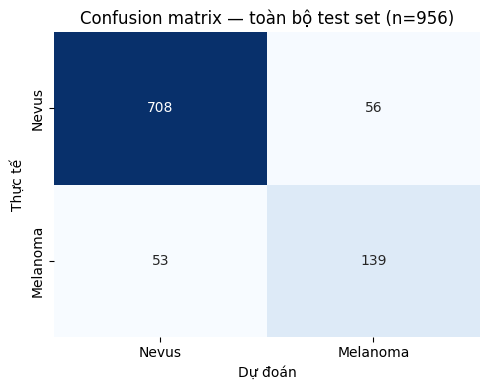

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(df_test['true'], df_test['pred'], labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Nevus', 'Melanoma'], yticklabels=['Nevus', 'Melanoma'], ax=ax,
)
ax.set_xlabel('Dự đoán')
ax.set_ylabel('Thực tế')
ax.set_title(f'Confusion matrix — toàn bộ test set (n={len(df_test)})')
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

y_true, y_pred = df_test['true'], df_test['pred']

print(f'Overall — n = {len(df_test)}, melanoma = {y_true.sum()}')
print(f'Accuracy : {accuracy_score(y_true, y_pred):.4f}')
print(f'Precision: {precision_score(y_true, y_pred):.4f}')
print(f'Recall   : {recall_score(y_true, y_pred):.4f}')
print(f'F1       : {f1_score(y_true, y_pred):.4f}')

Overall — n = 956, melanoma = 192
Accuracy : 0.8860
Precision: 0.7128
Recall   : 0.7240
F1       : 0.7183
